##WEEK 6 – FEATURE ENGINEERING

**Course:** 24ADI204 – Data Science and Visualization

**Project:** Credit Card Protection

**Dataset:** Credit Card Fraud Detection Dataset

**Aim:** Perform feature engineering, skewness correction, normalization, scaling and categorical encoding on the credit card fraud detection dataset.

TEAM MEMBERS:

*Abishake P      25BAD002

*ArunVignesh R S 25BAD012

*Nishanth M      25BAD069



## Import Libraries:

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

#from google.colab import files
from sklearn.preprocessing import MinMaxScaler, StandardScaler
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")

print("Libraries imported successfully.")

Libraries imported successfully.


## Load the cleaned dataset

In [7]:
#uploaded = files.upload()

#filename = next(iter(uploaded))

df = pd.read_csv("creditcard_cleaned.csv")

print("Dataset loaded successfully.")
print("Dataset shape:", df.shape)

display(df.head())

Dataset loaded successfully.
Dataset shape: (283726, 31)


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


## Inspect dataset columns

In [8]:
print("Dataset Columns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nClass Distribution:")
print(df["Class"].value_counts(dropna=False))

Dataset Columns:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Class']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 283726 entries, 0 to 283725
Data columns (total 31 columns):
 #   Column  Non-Null Count   Dtype  
---  ------  --------------   -----  
 0   Time    283726 non-null  float64
 1   V1      283726 non-null  float64
 2   V2      283726 non-null  float64
 3   V3      283726 non-null  float64
 4   V4      283726 non-null  float64
 5   V5      283726 non-null  float64
 6   V6      283726 non-null  float64
 7   V7      283726 non-null  float64
 8   V8      283726 non-null  float64
 9   V9      283726 non-null  float64
 10  V10     283726 non-null  float64
 11  V11     283726 non-null  float64
 12  V12     283726 non-null  float64
 13  V13     283726 non-null  float64
 14  V14     283726 non-null  float64


## Create new features:
We create new numerical features from the transaction amount.

Amount_log: Log-transformed transaction amount.
Amount_Category: Categorizes transactions into Low, Medium and High.

In [9]:
df_week6 = df.copy()

# Convert Class into numeric format
df_week6["Class"] = pd.to_numeric(
    df_week6["Class"], errors="coerce"
)

# Remove rows with missing target values
df_week6 = df_week6.dropna(subset=["Class"])

# Keep only valid target values
df_week6 = df_week6[df_week6["Class"].isin([0, 1])]

df_week6["Class"] = df_week6["Class"].astype(int)

# Create log-transformed Amount feature
df_week6["Amount_log"] = np.log1p(
    df_week6["Amount"].clip(lower=0)
)

# Create Amount Category
df_week6["Amount_Category"] = pd.cut(
    df_week6["Amount"],
    bins=[-np.inf, 100, 500, np.inf],
    labels=["Low", "Medium", "High"]
)

print("New features created successfully.")

display(
    df_week6[
        ["Amount", "Amount_log", "Amount_Category", "Class"]
    ].head(10)
)

New features created successfully.


,Amount,Amount_log,Amount_Category,Class
0,149.62,5.014760,Medium,0
1,2.69,1.305626,Low,0
2,378.66,5.939276,Medium,0
3,123.50,4.824306,Medium,0
4,69.99,4.262539,Low,0
5,3.67,1.541159,Low,0
6,4.99,1.790091,Low,0
7,40.80,3.732896,Low,0
8,93.20,4.545420,Low,0
9,3.68,1.543298,Low,0


## Prepare numerical features:
Select numerical features for statistical analysis and scaling.

In [10]:
# Select numerical columns except target Class
feature_columns = [
    col for col in df_week6.select_dtypes(include=np.number).columns
    if col != "Class"
]

X = df_week6[feature_columns].copy()

# Replace infinite values
X = X.replace([np.inf, -np.inf], np.nan)

# Fill missing values using median
X = X.fillna(X.median()).fillna(0)

print("Numerical Features:")
print(feature_columns)

display(X.describe().round(2))

Numerical Features:
['Time', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'V7', 'V8', 'V9', 'V10', 'V11', 'V12', 'V13', 'V14', 'V15', 'V16', 'V17', 'V18', 'V19', 'V20', 'V21', 'V22', 'V23', 'V24', 'V25', 'V26', 'V27', 'V28', 'Amount', 'Amount_log']


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Amount_log
count,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00,...,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00,283726.00
mean,94811.08,0.01,-0.00,0.00,-0.00,0.00,-0.00,0.00,-0.00,-0.00,...,-0.00,-0.00,0.00,0.00,-0.00,0.00,0.00,0.00,88.47,3.15
std,47481.05,1.95,1.65,1.51,1.41,1.38,1.33,1.23,1.18,1.10,...,0.72,0.72,0.62,0.61,0.52,0.48,0.40,0.33,250.40,1.66
min,0.00,-56.41,-72.72,-48.33,-5.68,-113.74,-26.16,-43.56,-73.22,-13.43,...,-34.83,-10.93,-44.81,-2.84,-10.30,-2.60,-22.57,-15.43,0.00,0.00
25%,54204.75,-0.92,-0.60,-0.89,-0.85,-0.69,-0.77,-0.55,-0.21,-0.64,...,-0.23,-0.54,-0.16,-0.35,-0.32,-0.33,-0.07,-0.05,5.60,1.89
50%,84692.50,0.02,0.06,0.18,-0.02,-0.05,-0.28,0.04,0.02,-0.05,...,-0.03,0.01,-0.01,0.04,0.02,-0.05,0.00,0.01,22.00,3.14
75%,139298.00,1.32,0.80,1.03,0.74,0.61,0.40,0.57,0.33,0.60,...,0.19,0.53,0.15,0.44,0.35,0.24,0.09,0.08,77.51,4.36
max,172792.00,2.45,22.06,9.38,16.88,34.80,73.30,120.59,20.01,15.59,...,27.20,10.50,22.53,4.58,7.52,3.52,31.61,33.85,25691.16,10.15


## Calculate skewness:
Skewness measures how much the distribution of a feature is asymmetric.

In [11]:
print("Skewness Before Transformation:")

display(
    X.skew().to_frame(name="Skewness").round(3)
)

Skewness Before Transformation:


,Skewness
Time,-0.036
V1,-3.273
V2,-4.695
V3,-2.152
V4,0.672
V5,-2.414
V6,1.830
V7,2.890
V8,-8.311
V9,0.538


## Visualize distribution before transformation:

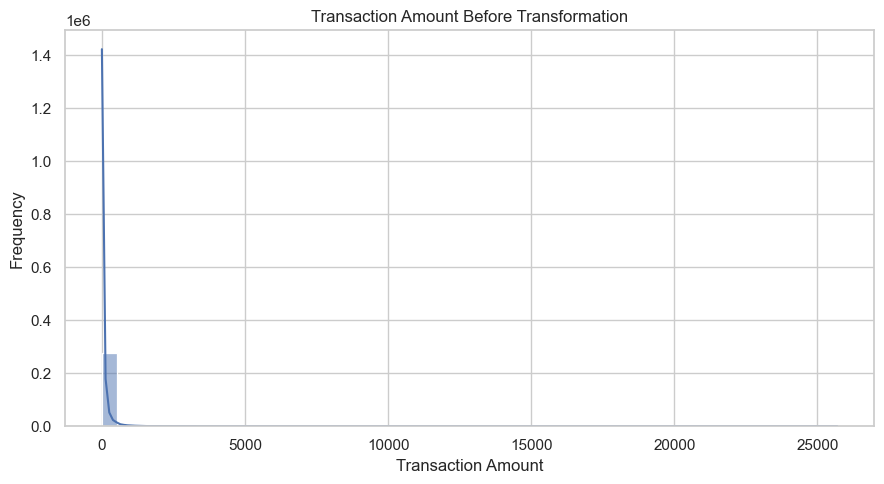

In [12]:
plt.figure(figsize=(9, 5))

sns.histplot(X["Amount"], kde=True, bins=50)

plt.title("Transaction Amount Before Transformation")
plt.xlabel("Transaction Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## Apply skewness correction:
Apply log transformation to the transaction amount.

In [13]:
df_week6["Amount_Log"] = np.log1p(
    df_week6["Amount"].clip(lower=0)
)

print("Skewness Before Transformation:")
print(df_week6["Amount"].skew())

print("\nSkewness After Transformation:")
print(df_week6["Amount_Log"].skew())

Skewness Before Transformation:
16.978803370060476

Skewness After Transformation:
0.16141018223366635


## Visualize distribution after transformation

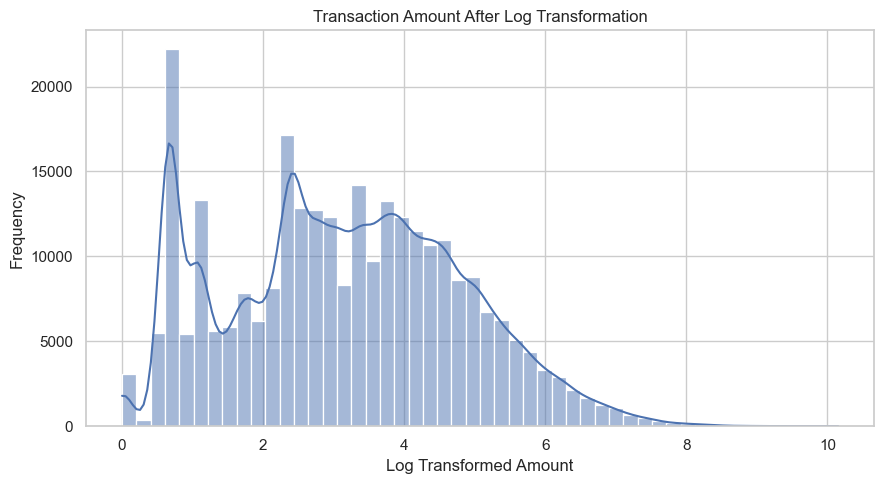

In [14]:
plt.figure(figsize=(9, 5))

sns.histplot(df_week6["Amount_Log"], kde=True, bins=50)

plt.title("Transaction Amount After Log Transformation")
plt.xlabel("Log Transformed Amount")
plt.ylabel("Frequency")

plt.tight_layout()
plt.show()

## One-Hot Encoding:
Convert the categorical feature Amount_Category into numerical columns.

In [15]:
category_encoded = pd.get_dummies(
    df_week6["Amount_Category"],
    prefix="Amount_Category",
    dtype=int
)

df_week6 = pd.concat(
    [df_week6, category_encoded],
    axis=1
)

print("One-Hot Encoding Completed!")

print("\nNew Encoded Columns:")
print(category_encoded.columns.tolist())

display(
    df_week6[
        ["Amount_Category"] + category_encoded.columns.tolist()
    ].head(10)
)

One-Hot Encoding Completed!

New Encoded Columns:
['Amount_Category_Low', 'Amount_Category_Medium', 'Amount_Category_High']


,Amount_Category,Amount_Category_Low,Amount_Category_Medium,Amount_Category_High
0,Medium,0,1,0
1,Low,1,0,0
2,Medium,0,1,0
3,Medium,0,1,0
4,Low,1,0,0
5,Low,1,0,0
6,Low,1,0,0
7,Low,1,0,0
8,Low,1,0,0
9,Low,1,0,0


## Prepare final features and target:
0 = Legitimate transaction
1 = Fraudulent transaction

In [16]:
# Exclude target and original categorical column
X = df_week6.drop(
    columns=["Class", "Amount_Category"]
)

y = df_week6["Class"]

# Ensure all input columns are numeric
X = X.apply(pd.to_numeric, errors="coerce")

X = X.replace([np.inf, -np.inf], np.nan)
X = X.fillna(X.median()).fillna(0)

print("Input Features Shape:", X.shape)
print("Target Shape:", y.shape)

Input Features Shape: (283726, 35)
Target Shape: (283726,)


## Split Training and Testing Data:
We divide the dataset into:

80% Training Data

20% Testing Data

In [17]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Data Shape: (226980, 35)
Testing Data Shape: (56746, 35)

Training Class Distribution:
Class
0    226602
1       378
Name: count, dtype: int64

Testing Class Distribution:
Class
0    56651
1       95
Name: count, dtype: int64


## Min-Max Normalization:
Min-Max Normalization converts continuous numerical features into a range between 0 and 1.

In [18]:
# Identify continuous numerical columns
continuous_columns = [
    col for col in X_train.columns
    if X_train[col].nunique() > 2
]

minmax_scaler = MinMaxScaler()

X_train_minmax = X_train.copy()
X_test_minmax = X_test.copy()

X_train_minmax[continuous_columns] = (
    minmax_scaler.fit_transform(
        X_train[continuous_columns]
    )
)

X_test_minmax[continuous_columns] = (
    minmax_scaler.transform(
        X_test[continuous_columns]
    )
)

print("Min-Max Normalization Completed!")

display(X_train_minmax.head())

Min-Max Normalization Completed!


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Amount_log,Amount_Log,Amount_Category_Low,Amount_Category_Medium,Amount_Category_High
225399,0.836549,0.996331,0.749062,0.732162,0.137658,0.494602,0.625105,0.536489,0.794612,0.419237,...,0.565612,0.399449,0.651061,0.255955,0.001628,0.353675,0.353675,1,0,0
133746,0.467128,0.935953,0.784466,0.795986,0.250230,0.473699,0.529819,0.562153,0.793274,0.419102,...,0.537884,0.381916,0.649457,0.258171,0.000356,0.210211,0.210211,1,0,0
185792,0.735659,0.990722,0.767482,0.733637,0.257662,0.497110,0.562855,0.559140,0.787319,0.472557,...,0.583862,0.426716,0.651270,0.255886,0.000761,0.280133,0.280133,1,0,0
148925,0.528624,0.989065,0.770599,0.789478,0.423938,0.480472,0.571580,0.549989,0.787892,0.486254,...,0.565977,0.423812,0.649458,0.256216,0.000880,0.294036,0.294036,1,0,0
18398,0.170853,0.981378,0.755431,0.794901,0.183324,0.461884,0.555919,0.543991,0.787669,0.390635,...,0.574298,0.353637,0.651770,0.257338,0.001221,0.325592,0.325592,1,0,0


## Standardization:
Standardization transforms numerical features to have approximately zero mean and unit standard deviation.

In [19]:
standard_scaler = StandardScaler()

X_train_standard = X_train.copy()
X_test_standard = X_test.copy()

X_train_standard[continuous_columns] = (
    standard_scaler.fit_transform(
        X_train[continuous_columns]
    )
)

X_test_standard[continuous_columns] = (
    standard_scaler.transform(
        X_test[continuous_columns]
    )
)

print("Standardization Completed!")

display(X_train_standard.head())

Standardization Completed!


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V25,V26,V27,V28,Amount,Amount_log,Amount_Log,Amount_Category_Low,Amount_Category_Medium,Amount_Category_High
225399,1.045499,1.147198,-1.042032,-1.428821,-1.817824,0.727198,2.695677,-1.489310,0.735746,-1.152704,...,-0.420363,-0.331281,0.092782,-0.156193,-0.229434,0.205510,0.205510,1,0,0
133746,-0.298690,-0.677911,0.991948,0.394668,-0.025642,-0.301198,-0.728240,0.175615,0.629070,-1.156290,...,-1.367338,-0.554255,-0.049864,0.153831,-0.331197,-0.650843,-0.650843,1,0,0
185792,0.678397,0.977654,0.016205,-1.386701,0.092688,0.850613,0.458823,-0.019872,0.154370,0.262056,...,0.202924,0.015479,0.111329,-0.165820,-0.298809,-0.233468,-0.233468,1,0,0
148925,-0.074929,0.927561,0.195261,0.208736,2.739855,0.032003,0.772348,-0.613532,0.199999,0.625478,...,-0.407893,-0.021447,-0.049724,-0.119582,-0.289247,-0.150483,-0.150483,1,0,0
18398,-1.376728,0.695218,-0.676118,0.363661,-1.090812,-0.882507,0.209618,-1.002620,0.182243,-1.911610,...,-0.123705,-0.913882,0.155776,0.037290,-0.261985,0.037881,0.037881,1,0,0


## Compare before and after scaling:

In [20]:
column = "Amount"

comparison = pd.DataFrame({
    "Original": X_train[column].head(10).values,
    "MinMax Normalized": X_train_minmax[column].head(10).values,
    "Standardized": X_train_standard[column].head(10).values
})

display(comparison)

,Original,MinMax Normalized,Standardized
0,32.00,0.001628,-0.229434
1,6.99,0.000356,-0.331197
2,14.95,0.000761,-0.298809
3,17.30,0.000880,-0.289247
4,24.00,0.001221,-0.261985
5,8.99,0.000457,-0.323059
6,29.95,0.001524,-0.237775
7,39.44,0.002006,-0.199161
8,5.12,0.000260,-0.338806
9,0.77,0.000039,-0.356506


Visual comparison:

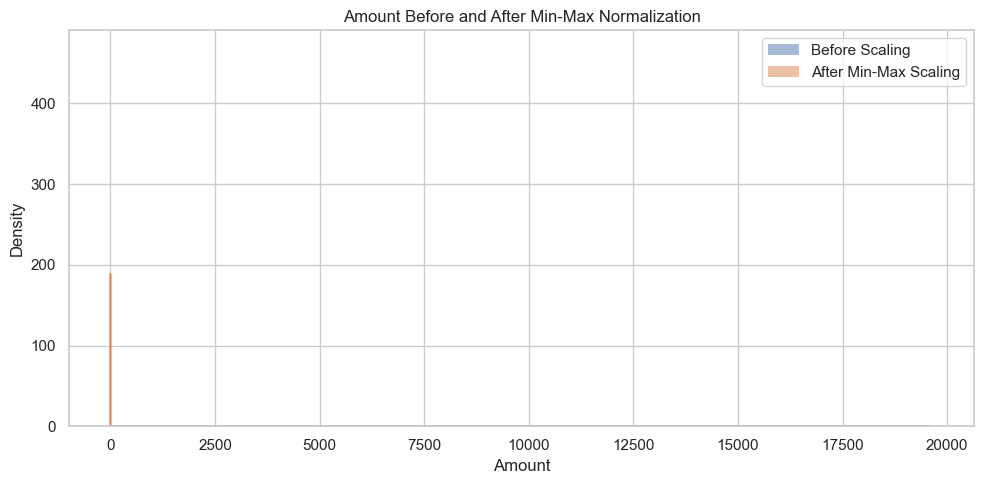

In [22]:
plt.figure(figsize=(10, 5))

sns.histplot(
    X_train["Amount"],
    label="Before Scaling",
    kde=True,
    stat="density"
)

sns.histplot(
    X_train_minmax["Amount"],
    label="After Min-Max Scaling",
    kde=True,
    stat="density"
)

plt.title("Amount Before and After Min-Max Normalization")
plt.xlabel("Amount")
plt.legend()

plt.tight_layout()
plt.show()

## Final Feature Engineering Report:

In [18]:
print("WEEK 6 - FEATURE ENGINEERING REPORT")
print("===================================")

print("Original Dataset Shape:", df.shape)

print("Final Dataset Shape:", df_week6.shape)

print("Total Missing Values:", df_week6.isnull().sum().sum())

print("\nNew Features Created:")
print(["Amount_log", "Amount_Category"])

print("\nOne-Hot Encoded Features:")
print(category_encoded.columns.tolist())

print("\nTraining Dataset Shape:", X_train.shape)
print("Testing Dataset Shape:", X_test.shape)

print("\nNormalized Features Summary:")

display(
    X_train_minmax[continuous_columns].describe().round(3)
)

print("\nWeek 6 Feature Engineering Completed Successfully!")

WEEK 6 - FEATURE ENGINEERING REPORT
Original Dataset Shape: (283726, 31)
Final Dataset Shape: (283726, 37)
Total Missing Values: 0

New Features Created:
['Amount_log', 'Amount_Category']

One-Hot Encoded Features:
['Amount_Category_Low', 'Amount_Category_Medium', 'Amount_Category_High']

Training Dataset Shape: (226980, 35)
Testing Dataset Shape: (56746, 35)

Normalized Features Summary:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V22,V23,V24,V25,V26,V27,V28,Amount,Amount_log,Amount_Log
count,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000,...,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000,226980.000
mean,0.549,0.958,0.767,0.782,0.252,0.480,0.550,0.559,0.785,0.463,...,0.510,0.665,0.414,0.578,0.425,0.650,0.257,0.004,0.319,0.319
std,0.275,0.033,0.017,0.035,0.063,0.020,0.028,0.015,0.013,0.038,...,0.034,0.009,0.088,0.029,0.079,0.011,0.007,0.013,0.168,0.168
min,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,...,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000
25%,0.314,0.943,0.761,0.762,0.214,0.469,0.534,0.552,0.783,0.441,...,0.485,0.663,0.362,0.560,0.372,0.648,0.256,0.000,0.192,0.192
50%,0.491,0.959,0.768,0.786,0.251,0.479,0.544,0.560,0.786,0.461,...,0.510,0.665,0.420,0.579,0.417,0.650,0.257,0.001,0.318,0.318
75%,0.807,0.981,0.776,0.806,0.285,0.489,0.558,0.567,0.789,0.483,...,0.535,0.668,0.478,0.598,0.465,0.653,0.259,0.004,0.442,0.442
max,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000,1.000



Week 6 Feature Engineering Completed Successfully!


In [23]:
# Save the feature-engineered dataset

df.to_csv("creditcard_week6.csv", index=False)

print("Week 6 CSV saved successfully!")

Week 6 CSV saved successfully!


## Conclusion:
In Week 6, we performed feature engineering on the dataset.
We applied log transformation to reduce skewness in transaction amounts.
We created amount categories and performed one-hot encoding.
We applied normalization and standardization to numerical features.